# 09 — Dependency topology via structured context occlusion

This experiment asks whether **where missing context is located** matters differently for human, GPT, and Claude text.

Standard context-length probing varies one deletion geometry:

\[
\text{keep the most recent }k\text{ tokens}.
\]

Here the corruption budget is fixed while the **spatial pattern** of removed context changes.

For every target token, start from the same 256-token context. Preserve the final 8 local tokens exactly, then remove 64 tokens from the older 248-token region using different patterns.

We use deletion rather than a literal `[MASK]` token because the causal scorer is not trained with a masked-token objective; injecting a mask token would create an out-of-distribution artifact.

For occlusion pattern \(M\),

\[
P_M(x)=L_M(x)-L_{256}(x)
\]

is the predictive cost of that occlusion.

To remove the generic cost of losing 64 tokens, define the **topology contrast**

\[
T_M(x)=P_M(x)-P_{\rm random}(x).
\]

Positive \(T_M\) means pattern \(M\) is more damaging than randomly deleting the same number of distant tokens.


## Pilot design

Default pilot:

- scorer: `Qwen/Qwen3-0.6B-Base`
- scorer prefix: 384 tokens
- 8 deterministic target positions
- base context: 256 tokens
- final 8 local tokens always preserved
- exactly 64 of the older 248 tokens removed
- 50 matched source groups per domain
- Essay, Reuters, Wikipedia
- Human, GPT, Claude
- 3 repetitions for stochastic patterns

Patterns:

1. random
2. periodic
3. contiguous
4. near
5. far

All retained tokens remain in original order.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"

SCORER_NAME = "Qwen/Qwen3-0.6B-Base"
PREFIX_LEN = 384
BASE_K = 256
LOCAL_KEEP = 8
REMOVE_N = 64
N_TARGETS = 8
N_STOCHASTIC_REPS = 3
N_GROUPS_PER_DOMAIN = 50
SEED = 1729
BATCH_SIZE = 32

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("ROOT:", ROOT)
print("device:", DEVICE)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
device: cuda


## Build matched Human/GPT/Claude groups


In [2]:
raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()

pool = raw[raw["generator"].isin(["human","gpt","claude"])].copy()
pool["group_key"] = pool["domain"].astype(str) + "::" + pool["group_id"].astype(str)

counts = pool.groupby("group_key")["generator"].agg(["size","nunique"])
complete_keys = counts.index[(counts["size"] == 3) & (counts["nunique"] == 3)]
pool = pool[pool["group_key"].isin(complete_keys)].copy()

pool = pool.merge(
    ctx[["row_id","context_loss_8","context_loss_256","context_u_256"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

eligible_keys = (
    pool.groupby("group_key")["generator"]
    .agg(["size","nunique"])
    .query("size == 3 and nunique == 3")
    .index
)
pool = pool[pool["group_key"].isin(eligible_keys)].copy()

print("eligible 3-way groups:", pool["group_key"].nunique())
display(pool.groupby(["domain","generator"]).size())

rng = np.random.default_rng(SEED)
chosen = []

for domain in sorted(pool["domain"].unique()):
    keys = np.array(sorted(pool.loc[pool["domain"] == domain, "group_key"].unique()))
    assert len(keys) >= N_GROUPS_PER_DOMAIN, (domain, len(keys))
    chosen.extend(rng.choice(keys, size=N_GROUPS_PER_DOMAIN, replace=False).tolist())

pilot = pool[pool["group_key"].isin(chosen)].copy()
pilot = pilot.sort_values(["domain","group_key","generator"]).reset_index(drop=True)

print("pilot groups:", pilot["group_key"].nunique())
print("pilot docs:", len(pilot))
display(pilot.groupby(["domain","generator"]).size())


eligible 3-way groups: 3000


domain  generator
essay   claude       1000
        gpt          1000
        human        1000
reuter  claude       1000
        gpt          1000
        human        1000
wp      claude       1000
        gpt          1000
        human        1000
dtype: int64

pilot groups: 150
pilot docs: 450


domain  generator
essay   claude       50
        gpt          50
        human        50
reuter  claude       50
        gpt          50
        human        50
wp      claude       50
        gpt          50
        human        50
dtype: int64

## Load scorer


In [3]:
tokenizer = AutoTokenizer.from_pretrained(SCORER_NAME)

dtype = torch.bfloat16 if DEVICE == "cuda" else torch.float32
model = AutoModelForCausalLM.from_pretrained(
    SCORER_NAME,
    dtype=dtype,
).to(DEVICE)
model.eval()

print("loaded:", SCORER_NAME)


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 14307.47it/s]


loaded: Qwen/Qwen3-0.6B-Base


## Occlusion operators

Each operator removes exactly 64 tokens from the older 248-token region. The final 8-token suffix remains unchanged.


In [4]:
def remove_by_indices(distant, remove_idx):
    remove_idx = set(int(i) for i in remove_idx)
    kept = [tok for i, tok in enumerate(distant) if i not in remove_idx]
    return torch.stack(kept)

def occlude_context(context_ids, pattern, rng):
    assert len(context_ids) == BASE_K

    distant = context_ids[:-LOCAL_KEEP]
    local = context_ids[-LOCAL_KEEP:]
    n = len(distant)

    if pattern == "random":
        remove_idx = rng.choice(n, size=REMOVE_N, replace=False)
    elif pattern == "periodic":
        remove_idx = np.linspace(0, n - 1, REMOVE_N, dtype=int)
    elif pattern == "contiguous":
        start = int(rng.integers(0, n - REMOVE_N + 1))
        remove_idx = np.arange(start, start + REMOVE_N)
    elif pattern == "near":
        remove_idx = np.arange(n - REMOVE_N, n)
    elif pattern == "far":
        remove_idx = np.arange(0, REMOVE_N)
    else:
        raise ValueError(pattern)

    retained = remove_by_indices(distant, remove_idx)
    out = torch.cat([retained, local], dim=0)

    assert len(out) == BASE_K - REMOVE_N
    assert torch.equal(out[-LOCAL_KEEP:], local)
    return out

toy = torch.arange(BASE_K)
for pattern in ["random","periodic","contiguous","near","far"]:
    out_ids = occlude_context(toy, pattern, np.random.default_rng(1))
    assert len(out_ids) == BASE_K - REMOVE_N
    assert torch.equal(out_ids[-LOCAL_KEEP:], toy[-LOCAL_KEEP:])

print("occlusion sanity checks passed")


occlusion sanity checks passed


## Frozen target positions and scoring


In [5]:
def target_positions(ids):
    available = np.arange(BASE_K, len(ids))
    if len(available) < N_TARGETS:
        return None
    return np.unique(np.linspace(BASE_K, len(ids)-1, N_TARGETS, dtype=int))

@torch.inference_mode()
def score_batch(sequences, targets):
    losses = []
    for start in range(0, len(sequences), BATCH_SIZE):
        seq_batch = torch.stack(sequences[start:start+BATCH_SIZE]).to(DEVICE)
        y = torch.stack(targets[start:start+BATCH_SIZE]).to(DEVICE)

        out = model(input_ids=seq_batch, logits_to_keep=1)
        logits = out.logits[:, -1, :].float()
        logp = torch.log_softmax(logits, dim=-1)
        nll = -logp[torch.arange(len(y), device=DEVICE), y]
        losses.extend(nll.detach().cpu().numpy().tolist())
    return np.asarray(losses, dtype=float)

PATTERN_SEEDS = {
    "random": 101,
    "periodic": 211,
    "contiguous": 307,
    "near": 401,
    "far": 503,
}

def score_pattern_for_document(text, pattern, row_seed):
    ids = tokenizer(
        str(text),
        add_special_tokens=False,
        return_tensors="pt",
    )["input_ids"][0][:PREFIX_LEN]

    positions = target_positions(ids)
    if positions is None:
        return np.nan, np.nan

    reps = N_STOCHASTIC_REPS if pattern in {"random","contiguous"} else 1
    rep_means = []

    for rep in range(reps):
        rng = np.random.default_rng(row_seed + 10007*rep + PATTERN_SEEDS[pattern])

        sequences = []
        targets = []
        for pos in positions:
            context = ids[pos-BASE_K:pos]
            occluded = occlude_context(context, pattern, rng)
            sequences.append(occluded)
            targets.append(ids[pos])

        rep_means.append(score_batch(sequences, targets).mean())

    sd = float(np.std(rep_means, ddof=1)) if len(rep_means) > 1 else 0.0
    return float(np.mean(rep_means)), sd


## Run pilot


In [6]:
PATTERNS = ["random","periodic","contiguous","near","far"]
rows = []

for i, r in enumerate(tqdm(pilot.itertuples(index=False), total=len(pilot), desc="Topology scoring")):
    rec = {
        "row_id": r.row_id,
        "group_key": r.group_key,
        "domain": r.domain,
        "generator": r.generator,
        "context_loss_8": r.context_loss_8,
        "context_loss_256": r.context_loss_256,
        "context_u_256": r.context_u_256,
    }

    for pattern in PATTERNS:
        loss, loss_sd = score_pattern_for_document(
            r.text,
            pattern,
            row_seed=SEED + i*1000003,
        )
        rec[f"loss_{pattern}"] = loss
        rec[f"loss_{pattern}_sd"] = loss_sd
        rec[f"cost_{pattern}"] = loss - r.context_loss_256

    rows.append(rec)

topo = pd.DataFrame(rows)

for pattern in ["periodic","contiguous","near","far"]:
    topo[f"topology_{pattern}"] = topo[f"cost_{pattern}"] - topo["cost_random"]

OUT_PATH = RESULTS / "dependency_topology_occlusion_pilot.parquet"
topo.to_parquet(OUT_PATH, index=False)

print("saved:", OUT_PATH)
display(topo.head())


Topology scoring: 100%|███████████████████████████████████████████████████████████████████████████████| 450/450 [06:36<00:00,  1.14it/s]

saved: ../results/dependency_topology_occlusion_pilot.parquet


,row_id,group_key,domain,generator,context_loss_8,context_loss_256,context_u_256,loss_random,loss_random_sd,cost_random,...,loss_near,loss_near_sd,cost_near,loss_far,loss_far_sd,cost_far,topology_periodic,topology_contiguous,topology_near,topology_far
0,claude_eval::essay::claude::124,essay::124,essay,claude,2.501337,0.830492,1.670844,1.480944,0.054264,0.650452,...,2.652556,0.0,1.822063,0.987901,0.0,0.157409,0.406528,-0.590959,1.171611,-0.493043
1,original::essay::gpt::124,essay::124,essay,gpt,3.859258,1.347787,2.511471,1.985346,0.151644,0.637559,...,3.008793,0.0,1.661006,1.440540,0.0,0.092753,0.165144,-0.510920,1.023447,-0.544806
2,original::essay::human::124,essay::124,essay,human,3.185234,2.185422,0.999812,2.542158,0.133354,0.356736,...,2.135614,0.0,-0.049808,2.316941,0.0,0.131519,-0.112951,-0.556981,-0.406543,-0.225216
3,claude_eval::essay::claude::129,essay::129,essay,claude,1.871918,0.652505,1.219413,1.172695,0.104514,0.520191,...,0.910427,0.0,0.257922,0.648843,0.0,-0.003662,0.221544,-0.432796,-0.262268,-0.523852
4,original::essay::gpt::129,essay::129,essay,gpt,0.700850,0.271160,0.429690,0.917728,0.115796,0.646569,...,1.043606,0.0,0.772447,0.226261,0.0,-0.044899,0.066196,-0.459329,0.125878,-0.691468


# Part I — Pattern costs and topology contrasts


In [7]:
COST_COLS = [f"cost_{p}" for p in PATTERNS]
TOPO_COLS = [f"topology_{p}" for p in ["periodic","contiguous","near","far"]]

display(
    topo.groupby("generator")[COST_COLS + TOPO_COLS]
    .agg(["mean","std","median","count"])
)


cost_random                           cost_periodic            \
                 mean       std    median count          mean       std   
generator                                                                 
claude       0.503741  0.306158  0.488666   149      0.661308  0.403319   
gpt          0.532302  0.283842  0.517549   143      0.780151  0.418840   
human        0.365819  0.307691  0.350521   141      0.528817  0.417440   

                          cost_contiguous            ... topology_contiguous  \
             median count            mean       std  ...              median   
generator                                            ...                       
claude     0.621049   149        0.108464  0.176984  ...           -0.385889   
gpt        0.748758   143        0.121489  0.173912  ...           -0.400972   
human      0.499730   141        0.079327  0.122869  ...           -0.261356   

                topology_near                           topology_far  \
          count          mean       std    median count         mean   
generator                                                              
claude      149      0.296772  0.501486  0.240378   149    -0.434749   
gpt         143      0.167764  0.497972  0.125878   143    -0.440837   
human       141      0.275345  0.494547  0.225202   141    -0.327278   

                                     
                std    median count  
generator                            
claude     0.307639 -0.395829   149  
gpt        0.312234 -0.431110   143  
human      0.325609 -0.311378   141  

[3 rows x 36 columns]

## Matched contrasts


In [8]:
contrast_rows = []

for feature in COST_COLS + TOPO_COLS:
    wide = topo.pivot(
        index=["domain","group_key"],
        columns="generator",
        values=feature,
    ).dropna()

    for a, b in [("gpt","human"),("claude","human"),("claude","gpt")]:
        d = wide[a] - wide[b]
        sd = d.std(ddof=1)

        contrast_rows.append({
            "feature": feature,
            "contrast": f"{a}-{b}",
            "n_groups": len(d),
            "mean_diff": d.mean(),
            "median_diff": d.median(),
            "paired_dz": d.mean()/sd if sd > 0 else np.nan,
            "positive_fraction": (d > 0).mean(),
        })

contrasts = pd.DataFrame(contrast_rows)
display(contrasts)

contrasts.to_csv(
    RESULTS / "dependency_topology_matched_contrasts.csv",
    index=False,
)


,feature,contrast,n_groups,mean_diff,median_diff,paired_dz,positive_fraction
0,cost_random,gpt-human,139,0.168577,0.159062,0.393745,0.676259
1,cost_random,claude-human,139,0.129943,0.125607,0.306306,0.582734
2,cost_random,claude-gpt,139,-0.038634,-0.058472,-0.090630,0.431655
3,cost_periodic,gpt-human,139,0.244642,0.168902,0.424382,0.647482
4,cost_periodic,claude-human,139,0.115121,0.082490,0.213758,0.546763
5,cost_periodic,claude-gpt,139,-0.129522,-0.026547,-0.226893,0.482014
6,cost_contiguous,gpt-human,139,0.041485,0.010214,0.206271,0.561151
7,cost_contiguous,claude-human,139,0.022998,0.010945,0.111925,0.539568
8,cost_contiguous,claude-gpt,139,-0.018487,-0.003554,-0.083368,0.489209
9,cost_near,gpt-human,139,0.064647,0.103298,0.084379,0.575540


# Part II — GPT-vs-Claude attribution beyond endpoint losses

If topology improves attribution beyond \(L_8,L_{256}\), deletion geometry carries source information beyond ordinary context-length probing.


In [9]:
machine_topo = topo[topo["generator"].isin(["gpt","claude"])].dropna(
    subset=["context_loss_8","context_loss_256",*TOPO_COLS]
).copy()
machine_topo["label"] = (machine_topo["generator"] == "claude").astype(int)

FEATURE_SETS = {
    "Endpoints": ["context_loss_8","context_loss_256"],
    "Endpoints+Topo": ["context_loss_8","context_loss_256",*TOPO_COLS],
    "TopoOnly": TOPO_COLS,
}

def make_clf():
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=3000,
            random_state=0,
        )),
    ])

group_keys = np.array(sorted(machine_topo["group_key"].unique()))
rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(group_keys))
    cut = int(.8*len(group_keys))
    tr_keys = set(group_keys[perm[:cut]])
    te_keys = set(group_keys[perm[cut:]])

    tr = machine_topo[machine_topo["group_key"].isin(tr_keys)]
    te = machine_topo[machine_topo["group_key"].isin(te_keys)]

    for method, cols in FEATURE_SETS.items():
        m = make_clf()
        m.fit(tr[cols], tr["label"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label"].to_numpy()

        rows.append({
            "seed": seed,
            "method": method,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

attrib = pd.DataFrame(rows)
display(attrib.groupby("method")[["auroc","balanced_accuracy","f1"]].mean().sort_values("auroc",ascending=False))

wide = attrib.pivot(index="seed", columns="method", values="auroc")
delta = wide["Endpoints+Topo"] - wide["Endpoints"]

print("Topology addition ΔAUROC")
print("mean:", delta.mean())
print("median:", delta.median())
print("IQR:", [delta.quantile(.25), delta.quantile(.75)])
print("positive:", int((delta > 0).sum()), "/ 20")

attrib.to_csv(RESULTS/"dependency_topology_attribution_splits.csv",index=False)


,auroc,balanced_accuracy,f1
method,,,
Endpoints+Topo,0.664297,0.638931,0.640290
Endpoints,0.634635,0.622189,0.622535
TopoOnly,0.596621,0.577778,0.595745


Topology addition ΔAUROC
mean: 0.029662685305768943
median: 0.03511904761904766
IQR: [np.float64(0.01077586206896558), np.float64(0.05450617283950626)]
positive: 16 / 20


# Part III — Human-vs-machine topology


In [10]:
hm = topo.dropna(subset=["context_loss_8","context_loss_256",*TOPO_COLS]).copy()
hm["label_machine"] = (hm["generator"] != "human").astype(int)

group_keys = np.array(sorted(hm["group_key"].unique()))
rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(group_keys))
    cut = int(.8*len(group_keys))
    tr_keys = set(group_keys[perm[:cut]])
    te_keys = set(group_keys[perm[cut:]])

    tr = hm[hm["group_key"].isin(tr_keys)]
    te = hm[hm["group_key"].isin(te_keys)]

    for method, cols in {
        "Endpoints": ["context_loss_8","context_loss_256"],
        "Endpoints+Topo": ["context_loss_8","context_loss_256",*TOPO_COLS],
        "TopoOnly": TOPO_COLS,
    }.items():
        m = make_clf()
        m.fit(tr[cols], tr["label_machine"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label_machine"].to_numpy()

        rows.append({
            "seed": seed,
            "method": method,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

hm_attrib = pd.DataFrame(rows)
display(hm_attrib.groupby("method")[["auroc","balanced_accuracy","f1"]].mean().sort_values("auroc",ascending=False))
hm_attrib.to_csv(RESULTS/"dependency_topology_human_machine_splits.csv",index=False)


,auroc,balanced_accuracy,f1
method,,,
Endpoints,0.743760,0.670955,0.750332
Endpoints+Topo,0.731825,0.659954,0.744217
TopoOnly,0.613355,0.576664,0.646524


# Part IV — Topology geometry


In [11]:
print("Pearson")
display(topo[TOPO_COLS].corr("pearson"))

print("Spearman")
display(topo[TOPO_COLS].corr("spearman"))

for g in ["human","gpt","claude"]:
    print(g.upper())
    display(topo.loc[topo["generator"]==g,TOPO_COLS].corr("pearson"))


Pearson


,topology_periodic,topology_contiguous,topology_near,topology_far
topology_periodic,1.000000,0.092163,0.074334,0.103450
topology_contiguous,0.092163,1.000000,0.137671,0.725655
topology_near,0.074334,0.137671,1.000000,0.017424
topology_far,0.103450,0.725655,0.017424,1.000000


Spearman


,topology_periodic,topology_contiguous,topology_near,topology_far
topology_periodic,1.000000,0.080466,0.069424,0.063268
topology_contiguous,0.080466,1.000000,0.160856,0.746242
topology_near,0.069424,0.160856,1.000000,0.069420
topology_far,0.063268,0.746242,0.069420,1.000000


HUMAN


,topology_periodic,topology_contiguous,topology_near,topology_far
topology_periodic,1.000000,0.093770,0.252057,0.164883
topology_contiguous,0.093770,1.000000,0.255743,0.710986
topology_near,0.252057,0.255743,1.000000,0.058746
topology_far,0.164883,0.710986,0.058746,1.000000


GPT


,topology_periodic,topology_contiguous,topology_near,topology_far
topology_periodic,1.000000,-0.010983,0.017859,-0.029583
topology_contiguous,-0.010983,1.000000,0.127823,0.639852
topology_near,0.017859,0.127823,1.000000,0.020368
topology_far,-0.029583,0.639852,0.020368,1.000000


CLAUDE


,topology_periodic,topology_contiguous,topology_near,topology_far
topology_periodic,1.000000,0.232686,0.004003,0.210244
topology_contiguous,0.232686,1.000000,0.013216,0.793933
topology_near,0.004003,0.013216,1.000000,-0.046880
topology_far,0.210244,0.793933,-0.046880,1.000000


# Part V — Figures


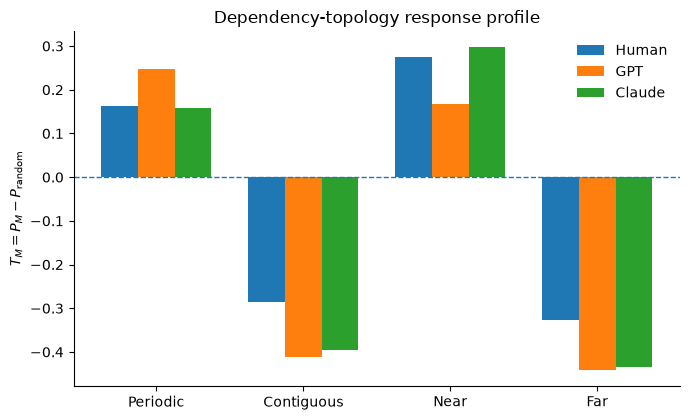

In [12]:
means = topo.groupby("generator")[TOPO_COLS].mean()

fig, ax = plt.subplots(figsize=(7.0,4.3))
x = np.arange(len(TOPO_COLS))
width = .25

for i, g in enumerate(["human","gpt","claude"]):
    ax.bar(
        x + (i-1)*width,
        means.loc[g].to_numpy(),
        width,
        label=("GPT" if g=="gpt" else g.capitalize()),
    )

ax.axhline(0,linestyle="--",linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(["Periodic","Contiguous","Near","Far"])
ax.set_ylabel(r"$T_M=P_M-P_{\rm random}$")
ax.set_title("Dependency-topology response profile")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES/"dependency_topology_profile.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"dependency_topology_profile.png",dpi=200,bbox_inches="tight")
plt.show()


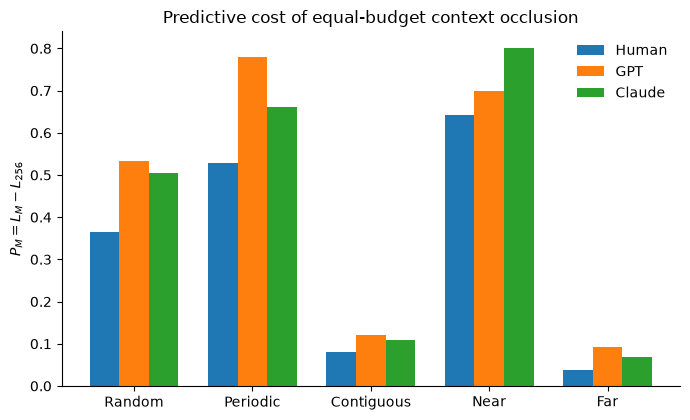

In [13]:
cost_means = topo.groupby("generator")[COST_COLS].mean()

fig, ax = plt.subplots(figsize=(7.0,4.3))
x = np.arange(len(COST_COLS))
width = .25

for i, g in enumerate(["human","gpt","claude"]):
    ax.bar(
        x + (i-1)*width,
        cost_means.loc[g].to_numpy(),
        width,
        label=("GPT" if g=="gpt" else g.capitalize()),
    )

ax.set_xticks(x)
ax.set_xticklabels(["Random","Periodic","Contiguous","Near","Far"])
ax.set_ylabel(r"$P_M=L_M-L_{256}$")
ax.set_title("Predictive cost of equal-budget context occlusion")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES/"dependency_topology_raw_costs.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"dependency_topology_raw_costs.png",dpi=200,bbox_inches="tight")
plt.show()


## Interpretation

The strongest result is **pattern specificity**: equal-budget deletion geometries have different relative costs, and those relative costs differ by source type.

If `Endpoints+Topo > Endpoints`, topology reveals source information beyond ordinary short/long-context losses.

If all topology contrasts are near zero or highly collinear, structured deletion geometry adds little under this scorer.

Important limitation: token deletion changes adjacency and relative positions. This probes sensitivity to structured context removal, not a pure causal map of latent dependencies.


In [14]:
def fs(x):
    return f"{x:+.5f}"

print("MATCHED TOPOLOGY CONTRASTS")
for contrast in ["gpt-human","claude-human","claude-gpt"]:
    print("\n"+contrast)
    sub = contrasts[
        (contrasts["contrast"] == contrast)
        & (contrasts["feature"].isin(TOPO_COLS))
    ]
    for r in sub.itertuples(index=False):
        print(
            r.feature,
            "| mean", fs(r.mean_diff),
            "| dz", f"{r.paired_dz:+.3f}",
            "| n", int(r.n_groups),
        )

print("\nGPT-vs-CLAUDE ATTRIBUTION")
print(
    "Endpoints+Topo - Endpoints",
    "| mean ΔAUROC", fs(delta.mean()),
    "| median", fs(delta.median()),
    "| IQR", f"[{fs(delta.quantile(.25))}, {fs(delta.quantile(.75))}]",
    "| positive", f"{int((delta > 0).sum())}/20",
)


MATCHED TOPOLOGY CONTRASTS

gpt-human
topology_periodic | mean +0.07607 | dz +0.182 | n 139
topology_contiguous | mean -0.12709 | dz -0.305 | n 139
topology_near | mean -0.10393 | dz -0.138 | n 139
topology_far | mean -0.11556 | dz -0.256 | n 139

claude-human
topology_periodic | mean -0.01482 | dz -0.037 | n 139
topology_contiguous | mean -0.10695 | dz -0.281 | n 139
topology_near | mean +0.01966 | dz +0.028 | n 139
topology_far | mean -0.10422 | dz -0.227 | n 139

claude-gpt
topology_periodic | mean -0.09089 | dz -0.221 | n 139
topology_contiguous | mean +0.02015 | dz +0.051 | n 139
topology_near | mean +0.12359 | dz +0.169 | n 139
topology_far | mean +0.01133 | dz +0.026 | n 139

GPT-vs-CLAUDE ATTRIBUTION
Endpoints+Topo - Endpoints | mean ΔAUROC +0.02966 | median +0.03512 | IQR [+0.01078, +0.05451] | positive 16/20
